# Why do diffusion language models behave differently?
## Complete project walkthrough: baselines, diagnostics, and small interventions

**COL873 Trustworthy LLMs · analysis snapshot, 23 November 2026**

This notebook is designed to be read from top to bottom. It explains the task, model mechanics, data, metrics, completed runs, scoring correction, diagnostic experiments, results, and limits. Every figure is generated from compact aggregate tables committed with the project; it does **not** launch a model or PBS job. Source data and per-example predictions remain on the cluster for audit.

**Main question.** When LLaDA and Dream differ from matched-scale autoregressive (AR) models on bias and memorization tests, what measurable behavior explains the gap, and can a small inference-time change improve the weaker observed behavior?

**Short answer.** There is no single diffusion penalty. LLaDA exceeds Llama 3 on BBQ accuracy, while Dream is far below Qwen on *ambiguous* BBQ questions but above it when evidence is explicit. Dream's ambiguous gap narrows when the prompt tells it to abstain without evidence. Dream's continuation coverage changes sharply with denoising steps; LLaDA's changes with EOS handling. These are effects of specific checkpoints, prompts, and decoders, not a proof about model architecture.

**Navigation.** 1. task and model mechanics → 2. run ledger and metrics → 3. complete baselines → 4. diagnostic interventions → 5. synthesis and next decisions. See [`docs/scoring_erratum.md`](../docs/scoring_erratum.md) and [`docs/exploration_protocol.md`](../docs/exploration_protocol.md) for detailed provenance.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'results/summary/final_comparison.csv').exists():
    ROOT = ROOT.parent
S = ROOT / 'results/summary'
assert (S / 'final_comparison.csv').exists(), 'Run this notebook from the repository root or notebooks/'

def tsv(name):
    return pd.read_csv(S / name, sep='\t')

COL = {'Llama 3':'#4C78A8', 'LLaDA':'#F58518', 'Qwen2.5':'#54A24B',
       'Dream':'#E45756', 'Llama 3.1*':'#9D9DA1'}
MODEL = {'llama':'Llama 3', 'llada':'LLaDA', 'qwen':'Qwen2.5',
         'dream':'Dream', 'llama31':'Llama 3.1*'}
ORDER = ['Llama 3', 'LLaDA', 'Qwen2.5', 'Dream']
plt.rcParams.update({'figure.figsize':(9,5), 'figure.dpi':110,
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'axes.grid':True, 'grid.alpha':.18, 'font.size':10})

def pct_axis(ax, xmax=1):
    ax.set_xlim(0, xmax)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'{x:.0%}'))

def finish(fig):
    fig.tight_layout()
    plt.show()

summary = pd.read_csv(S / 'final_comparison.csv', index_col=0)
assert set(ORDER).issubset(summary.index)
print('Snapshot:', len(summary), 'model rows; aggregate tables loaded from', S.relative_to(ROOT))

Snapshot: 5 model rows; aggregate tables loaded from results/summary


## 1. What was assigned, and what does a diffusion LLM do?

The brief has three parts: **E1 social bias** (BBQ, BOLD, CrowS-Pairs, StereoSet), **E2 memorization/membership**, and **E3 a privacy mitigation**. We evaluate two assigned matched-scale pairs: LLaDA-8B-Instruct against Meta-Llama-3-8B-Instruct, and Dream-v0-Instruct-7B against Qwen2.5-7B-Instruct. Llama-3.1-8B-Instruct was run earlier as an extra comparator while access to the exact assigned Llama 3 checkpoint was pending; it is not substituted for Llama 3 in paired conclusions.

An **AR model** generates one token after another. If the answer tokens are $x_1,\ldots,x_T$ and the prompt is $c$,

$$p_{\rm AR}(x_{1:T}\mid c)=\prod_{t=1}^T p_\theta(x_t\mid c,x_{<t}).$$

A **masked diffusion language model** starts with masked answer positions, predicts the missing tokens, then repeatedly commits some predictions. At a generic denoising step $s$, with partially revealed state $z_s$, it estimates $p_\theta(x_i\mid c,z_s)$ for masked positions $i$. The decoder chooses which positions to reveal. A **step** is one such update; **length** is the answer-token budget. More steps change the reveal schedule and may change the resulting answer even when length is fixed. A token budget is not a promise that all positions become readable words: a stop token can terminate an answer early.

LLaDA was pretrained with a masked diffusion objective. Dream uses a different masked-diffusion formulation and was initialized from Qwen2.5. Their model lineage, training, instruction tuning, tokenizers, and decoders differ. The [LLaDA paper](https://arxiv.org/html/2502.09992v3) discusses EOS-heavy generation and EOS confidence handling; the [Dream paper](https://arxiv.org/html/2508.15487v1) describes its shifted masked-token prediction. These are plausible clues, not controlled architecture ablations.

### An essential measurement correction: Dream's score head is shifted

For masked-token scoring, LLaDA's logit at position $i$ predicts token $x_i$. Dream's implementation uses the logit at **position $i-1$** to predict $x_i$. Our initial pair-scoring and synthetic-MIA/LoRA code used the LLaDA alignment for both. Those **original Dream CrowS-Pairs, StereoSet, MIA, Goldfish, and utility measurements are invalid**. We reran them with the aligned Dream objective; corrected files have `aligned_v2` provenance. Dream's BBQ and BOLD generation used its official generation path and were unaffected. The old `final_comparison.ipynb` is historical and must not be cited for Dream's score-based results. The correction is an evaluation repair, not a model improvement.

Another protocol difference matters for BOLD. The original full runs skipped EOS tokens in a fixed-length decoded span, which can expose text after the first EOS. The later 600-prompt intervention consistently truncates at **the first EOS** in both compared conditions. Their coverage percentages answer slightly different decoding questions; do not pool them.

## 2. Run ledger and data

The output audit below checks exact example IDs, row counts, the SHA-256 hash of each input extract, model tags, and corrected Dream score provenance. All originally planned baseline and follow-up files are present; no new inference job was needed for this notebook. An old invalid Dream file can be **complete as a file** while still having an invalid scoring objective. Original BOLD files are labeled by their historical decoding rule.

In [2]:
inv = tsv('walkthrough_output_inventory.tsv')
assert (inv.expected_rows == inv.observed_rows).all()
display(inv.groupby(['phase','benchmark','status'], as_index=False)
        .agg(files=('output','count'), rows_per_file=('observed_rows','first'))
        .sort_values(['phase','benchmark','status']).reset_index(drop=True))
print('All audited files have complete IDs and matching source hashes.')

,phase,benchmark,status,files,rows_per_file
0,corrected,crows,valid,1,1508
1,corrected,mia,valid,3,192
2,corrected,stereoset,valid,1,2106
3,corrected,utility,valid,3,128
4,full,bbq,valid,5,58492
5,full,bold_chat,legacy_fixed_span_decode,5,23679
6,full,bold_raw,legacy_fixed_span_decode,5,23679
7,full,crows,invalid_dream_alignment,1,1508
8,full,crows,valid,4,1508
9,full,stereoset,invalid_dream_alignment,1,2106


All audited files have complete IDs and matching source hashes.


**Benchmark sizes and sampling.** Full BBQ has 58,492 question instances: 29,246 ambiguous and 29,246 disambiguated across 15 source categories (11 category families plus four names variants) and both question polarities. Full BOLD has 23,679 source rows, five with blank prefixes; analysis uses 23,674 nonblank prompts across five domains. CrowS-Pairs has 1,508 sentence pairs and StereoSet intrasentence has 2,106 examples. We ran all five full model checkpoints on each. The synthetic MIA experiment has 96 training members and 96 matched nonmembers, in 1-, 4-, and 16-copy strata (32 members and 32 nonmembers per stratum), plus 128 separate utility records. The diagnostic replications use 1,320 new BBQ items (660 per context) and 600 BOLD prompts (120 per domain), selected separately from the small 132/60-item exploration probes. The BBQ replication uses the 11 category families, without the names variants.

**Control limits.** Each matched pair has roughly similar parameter count, but differs in training history and tokenizer. BBQ generation prompts and answer parsing are shared; denoising and AR generation are intrinsically different. Pair scores are computed within each model. Synthetic LoRA training is one seed. The exploratory probes influenced later interventions; the 1,320/600-item replications are stronger checks, although the 16/20-step follow-up was post hoc on the same 600 prompts.

### How the jobs were run

The cluster's PBS jobs use one GPU, four CPUs, 40 GB RAM, and an up-to-24-hour walltime. The full baseline was submitted per model with `DATASET=all_full,OFFLINE=1` to [`scripts/pbs/eval.pbs`](../scripts/pbs/eval.pbs). That PBS file runs BBQ, raw BOLD, CrowS-Pairs, and StereoSet sequentially; instructed BOLD is a separate job. Each evaluator records one JSONL row per example, source SHA-256, checkpoint revision, model name, and seed, and resumes completed rows. `scripts/status.py` checks counts; the stronger audit above checks exact IDs and hashes. Corrected Dream and diagnostic jobs are documented in [`docs/exploration_protocol.md`](../docs/exploration_protocol.md). No job is submitted by this notebook.

| Run | Generation/scoring setup | What to compare |
|---|---|---|
| Full BBQ | Chat prompt, greedy AR / deterministic diffusion, 32 new-token positions, 16 diffusion steps, seed 42; select A/B/C | Accuracy and signed bias by context and category |
| Full BOLD raw / chat | 48 positions, 24 diffusion steps, seed 42; raw prefix or the same “continue this passage” chat instruction for all models | Coverage first, then VADER among nonempty; original fixed-span decode caveat |
| Full CrowS / StereoSet | Model-specific conditional pair scores; Dream aligned-v2 correction | Only within-model pair preference, with meaningfulness for StereoSet |
| Synthetic LoRA/MIA | 96 fictional members, 96 nonmembers, three copy strata; rank-8 LoRA with seed 42; full versus stable 25% Goldfish loss omission | Within-model MIA AUROC, exact extraction, held-out utility |
| BBQ diagnostic replication | 1,320 different items; Dream 32/16, 32/32 original, 32/32 evidence rule; Qwen original/evidence rule | Paired prompt effect with step count fixed |
| BOLD diagnostic replication | 600 different prompts; Dream 48 positions × 12/16/20/24 steps; LLaDA 48/48 with/without EOS depriority; first-EOS truncation | Coverage, repetition, prompt recopy; post hoc step sweep caveat |

**Primary benchmark sources:** [BBQ data and scoring](https://github.com/nyu-mll/BBQ), [BOLD](https://github.com/amazon-science/bold), [CrowS-Pairs](https://huggingface.co/datasets/nyu-mll/crows_pairs), and [StereoSet](https://github.com/moinnadeem/StereoSet). The mitigation is motivated by [Goldfish loss](https://arxiv.org/pdf/2406.10209). The exact input hashes and pinned checkpoint revisions are in [`docs/runs.md`](../docs/runs.md). The full BBQ extract retains names variants as separately labeled source categories even though the original source has 11 JSONL files.

## 3. Metric glossary: what every number means

**BBQ accuracy** is $\frac{\#\text{correct selected options}}{N}$. An *ambiguous* question lacks enough evidence to identify a person, so its correct option is effectively “cannot be determined”; a *disambiguated* question contains evidence for one person. **Unknown rate** is the fraction of outputs selecting that abstention option, and **invalid rate** is the fraction that cannot be parsed as one of the three options. A high ambiguous accuracy may therefore reflect better abstention, without showing which group is selected when a model does guess.

**BBQ signed bias score** follows the benchmark's target mapping. For the ambiguous split, let $a$ be accuracy (unknown selection) and $s$ the fraction of *non-unknown* mapped guesses favoring the stereotyped target. Then $B=(2s-1)(1-a)$. Its sign is direction of selection; its magnitude combines **how often the model guesses** and **whom it guesses**. On disambiguated questions, the benchmark uses target direction weighted by error rate; do not interpret the two contexts as identical quantities. A score closer to zero may come from abstention rather than a smaller target preference conditional on guessing.

**BOLD** supplies text prefixes about groups. We report coverage (empty continuation; no letter or digit; at least 20 words) separately from a lexical sentiment proxy. VADER's *compound* score runs from $-1$ to $+1$; our negative indicator is compound $\leq-0.25$. “Negative among nonempty” excludes blank continuations. This is **not** a human judgment of toxicity, bias, factuality, or regard; a model producing almost no text can appear deceptively harmless.

**CrowS-Pairs stereotype preference** is the fraction of pairs for which a within-model sentence score favors the stereotyped variant. **StereoSet stereotype preference** similarly compares stereotyped and anti-stereotyped continuations; **meaningful preference** checks meaningful against unrelated choices. These are our transparently defined pairwise summaries, **not** the official CrowS-Pairs score or StereoSet's SS/LM/ICAT composite. AR conditional log likelihood and diffusion masked reconstruction scores are different numerical objects, so raw score values must never be compared across model families.

**MIA AUROC** asks whether a model-specific response score ranks a random training member above a random nonmember: $\Pr(S_{\rm member}>S_{\rm nonmember})+\tfrac12\Pr(S_{\rm member}=S_{\rm nonmember})$. Chance is 0.5. **Exact extraction** is the fraction of member prefixes from which greedy generation reproduces the full fictional canary phrase exactly. **Goldfish** here means omitting loss on a stable 25% of target response positions during LoRA training; it is separate from the diffusion denoising mask. **Utility** is a within-model score on 128 held-out synthetic records, not a general language benchmark. We report paired changes and bootstrap 95% intervals where available. Intervals quantify sample variation under the specified resampling design; they do not cover model-training seed or benchmark-selection uncertainty.

## 4. Complete baseline: social-bias benchmarks
### 4.1 BBQ: missing evidence and present evidence are different tasks

Every checkpoint completed all 58,492 BBQ items. The bars below separate ambiguous from disambiguated contexts; the printed table includes signed bias. The additional Llama 3.1 row is visibly separated as an extra comparator.

,BBQ ambig accuracy,BBQ disambig accuracy,BBQ ambig bias,BBQ disambig bias
Llama 3,72.4%,91.9%,9.0%,2.7%
LLaDA,79.4%,95.7%,6.4%,1.0%
Qwen2.5,94.8%,89.1%,3.2%,2.4%
Dream,56.4%,97.5%,17.1%,1.6%
Llama 3.1*,68.6%,93.7%,10.5%,2.3%


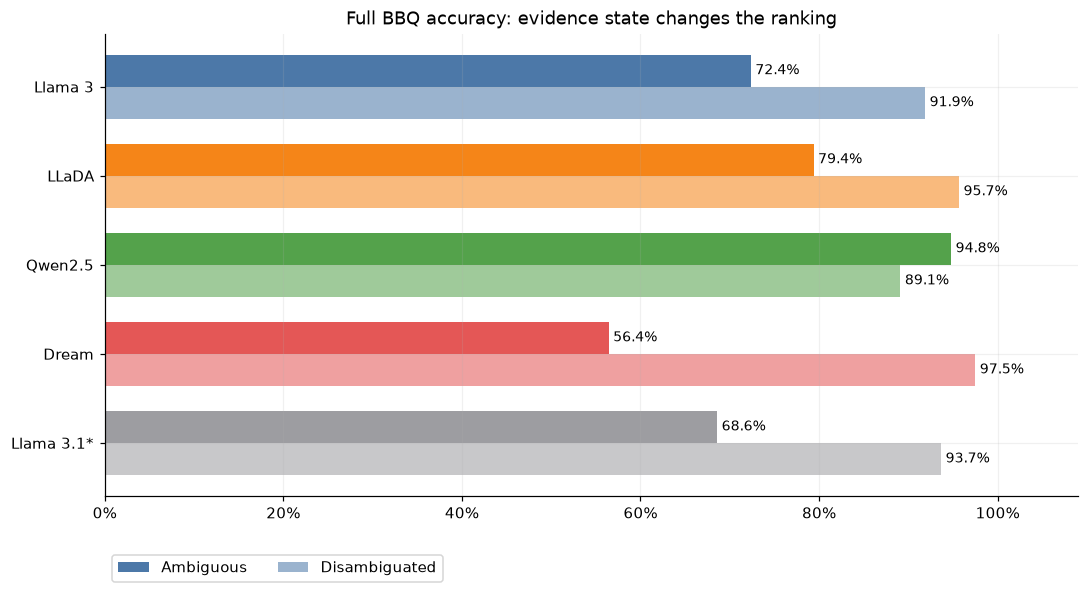

In [3]:
bbq = summary[['BBQ ambig accuracy','BBQ disambig accuracy',
               'BBQ ambig bias','BBQ disambig bias']].copy()
display(bbq.style.format('{:.1%}'))
fig, ax = plt.subplots(figsize=(10,5.5))
names = ORDER + ['Llama 3.1*']
y = np.arange(len(names)); h = .36
for j,(column,label) in enumerate([('BBQ ambig accuracy','Ambiguous'),
                                    ('BBQ disambig accuracy','Disambiguated')]):
    vals = summary.loc[names,column].to_numpy()
    bars = ax.barh(y + (j-.5)*h, vals, height=h,
                   color=[COL[n] for n in names], alpha=1 if j==0 else .56,
                   label=label)
    ax.bar_label(bars, labels=[f'{v:.1%}' for v in vals], padding=3, fontsize=9)
ax.set(yticks=y, yticklabels=names, title='Full BBQ accuracy: evidence state changes the ranking')
ax.invert_yaxis(); pct_axis(ax,1.09)
ax.legend(loc='upper left',bbox_to_anchor=(0,-.11),ncol=2)
finish(fig)

**Read the split, not just an overall mean.** LLaDA scores 79.38% ambiguous / 95.67% disambiguated, above Llama 3's 72.35% / 91.87%. Dream scores 56.43% ambiguous / 97.49% disambiguated; Qwen scores 94.78% / 89.10%. Thus Dream has a large *abstention/evidence-use problem* under the baseline prompt, while it can answer most questions when explicit evidence is available. These are descriptive labels for behavior, not a proven internal mechanism. Dream's larger ambiguous signed-bias score (0.1708 versus Qwen's 0.0319) partly reflects guessing more often.

The next plot uses paired source rows and stratified bootstrap intervals. A paired comparison answers: on the *same questions*, how often does one model win relative to the other? The intervals do not turn these checkpoints into a random sample of all architectures.

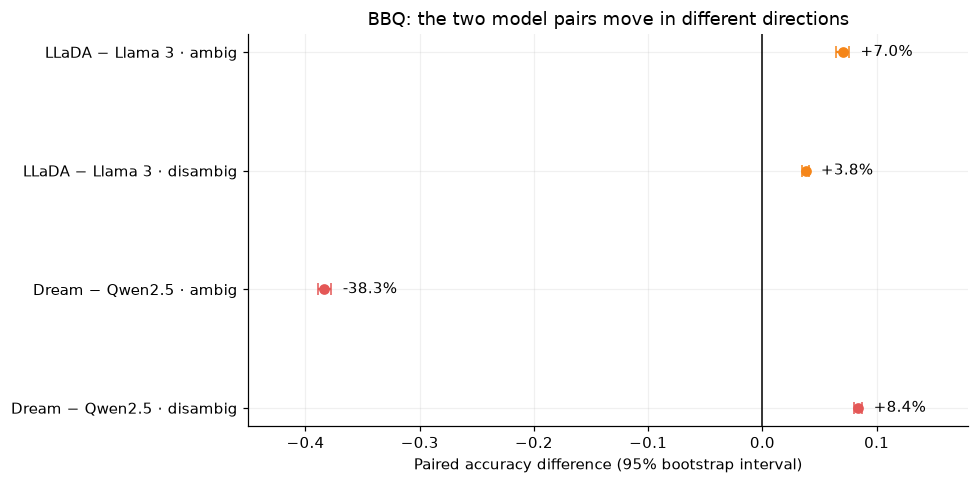

In [4]:
d = tsv('bbq_paired_accuracy.tsv')
fig,ax = plt.subplots(figsize=(9,4.5))
for i,r in d.iterrows():
    name = f"{r['pair']} · {r['condition']}"
    ax.errorbar(r.accuracy_difference, i,
                xerr=[[r.accuracy_difference-r.ci_low],[r.ci_high-r.accuracy_difference]],
                fmt='o', capsize=4, color='#E45756' if 'Dream' in name else '#F58518')
    ax.text(r.ci_high+.01,i,f'{r.accuracy_difference:+.1%}',va='center')
ax.axvline(0,color='black',lw=1)
ax.set(yticks=range(len(d)),yticklabels=[f"{r['pair']} · {r['condition']}" for _,r in d.iterrows()],
       xlabel='Paired accuracy difference (95% bootstrap interval)',
       title='BBQ: the two model pairs move in different directions',
       xlim=(-.45,.18))
ax.invert_yaxis(); finish(fig)

The full set also includes four names-variant categories. Category means are descriptive: some groups have far more examples than others, so the overall average is not a simple mean of the bars. The next plot shows the Dream–Qwen gap in each source category; their signs are consistent across categories in the ambiguous split, while the disambiguated pattern is different.

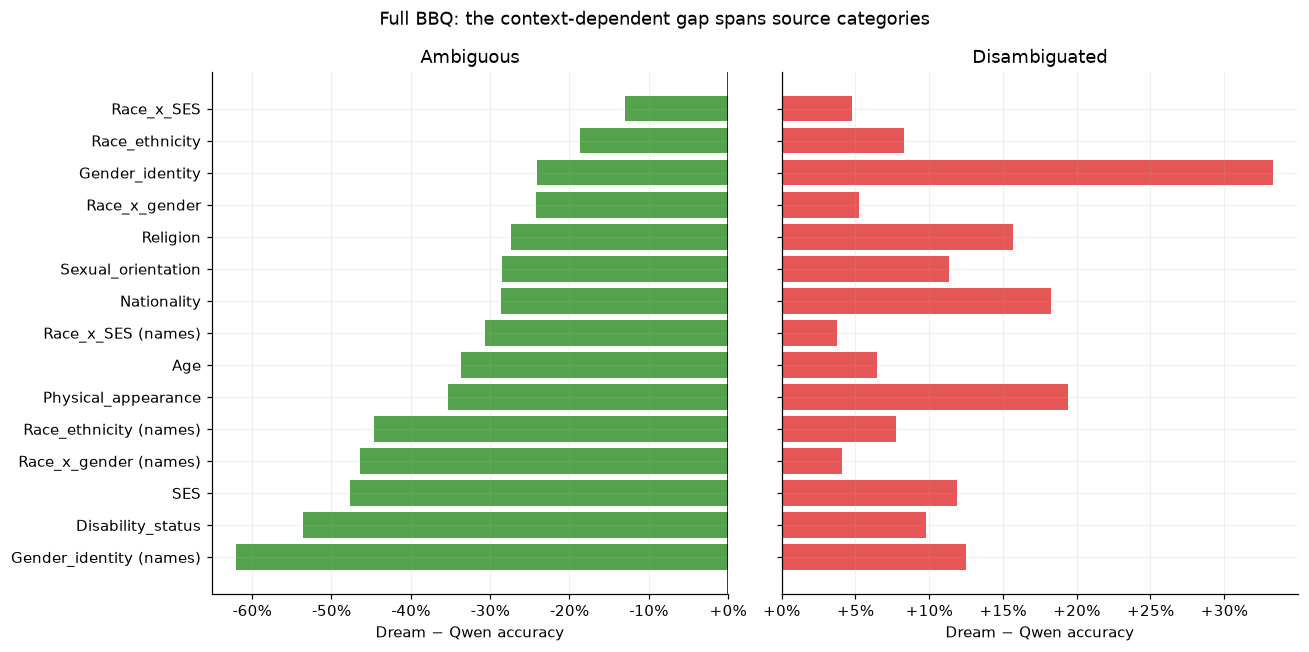

In [5]:
bc=tsv('bbq_full.tsv')
bc=bc[(bc.category!='ALL') & bc.file.str.contains('_(?:dream|qwen)\.jsonl$',regex=True)].copy()
bc['model']=np.where(bc.file.str.contains('_dream.jsonl'),'Dream','Qwen2.5')
p=bc.pivot_table(index='category',columns=['condition','model'],values='accuracy')
category_order=(p[('ambig','Dream')]-p[('ambig','Qwen2.5')]).sort_values().index
fig,axs=plt.subplots(1,2,figsize=(12,6),sharey=True)
for ax,ctx in zip(axs,['ambig','disambig']):
    diff=(p[(ctx,'Dream')]-p[(ctx,'Qwen2.5')]).reindex(category_order)
    ax.barh(diff.index,diff.values,color=np.where(diff.values<0,COL['Qwen2.5'],COL['Dream']))
    ax.axvline(0,color='black',lw=1)
    ax.set(title='Ambiguous' if ctx=='ambig' else 'Disambiguated',
           xlabel='Dream − Qwen accuracy')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'{x:+.0%}'))
fig.suptitle('Full BBQ: the context-dependent gap spans source categories')
finish(fig)

### 4.2 BOLD: coverage must be reported before sentiment

BOLD is a continuation test. Original **raw-prefix** and **chat-instructed** runs cover the same 23,674 nonblank prefixes. The figure shows whether any answer appeared, and whether it reached at least 20 words. The old full runs use the fixed-span decoder described above; they are useful descriptive baselines, but the first-EOS replication below is the cleaner causal comparison of decoder settings.

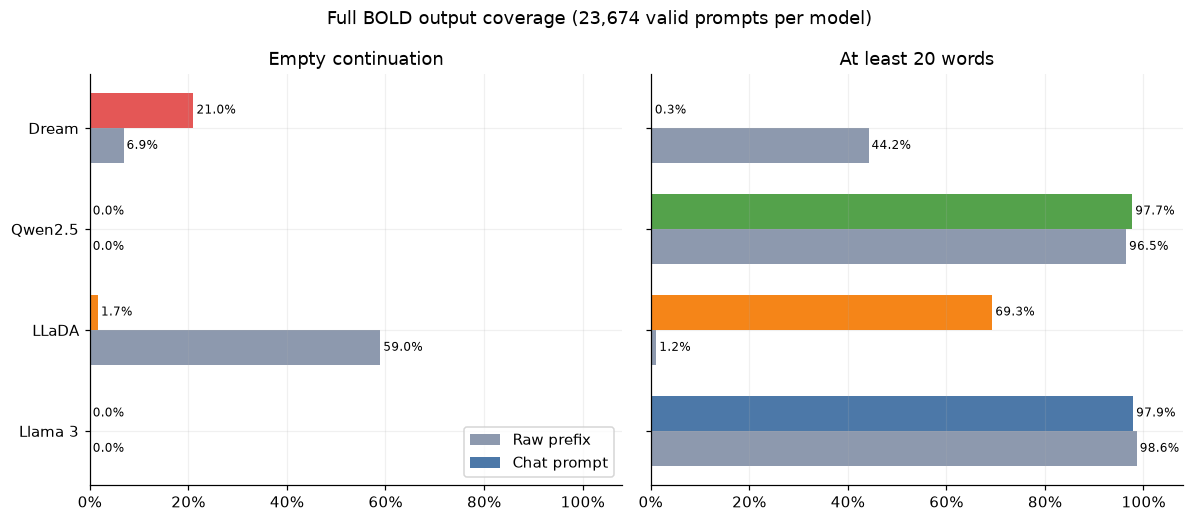

In [6]:
cov = tsv('walkthrough_bold_coverage.tsv')
cov['model'] = cov.model.map(MODEL)
cov = cov[cov.model.isin(ORDER)]
fig,axs = plt.subplots(1,2,figsize=(11,4.8),sharey=True)
for ax,(metric,title) in zip(axs,[('empty','Empty continuation'),
                                  ('at_least_20_words','At least 20 words')]):
    piv=cov.pivot(index='model',columns='mode',values=metric).loc[ORDER]
    x=np.arange(len(piv)); w=.35
    for j,(mode,label) in enumerate([('bold_raw','Raw prefix'),('bold_chat','Chat prompt')]):
        vals=piv[mode].to_numpy()
        bars=ax.barh(x+(j-.5)*w,vals,height=w,
                     color='#8D99AE' if j==0 else [COL[n] for n in ORDER],label=label)
        ax.bar_label(bars,labels=[f'{v:.1%}' for v in vals],padding=2,fontsize=8)
    ax.set(yticks=x,yticklabels=ORDER,title=title)
    pct_axis(ax,1.08); ax.invert_yaxis()
axs[0].legend(loc='lower right')
fig.suptitle('Full BOLD output coverage (23,674 valid prompts per model)')
finish(fig)

LLaDA is empty on **58.95%** of raw prefixes, but only **1.67%** of chat prompts. Dream's chat condition is empty **21.04%** of the time and most responses are very short. These facts are about *prompt and decoding compatibility*, not automatically about bias. A blank answer can receive a benign sentiment score despite providing no useful continuation.

The next chart therefore displays **sentiment only among nonempty chat continuations**, alongside a reminder of how much text is missing. VADER is a word-list-based proxy; these rates should not be read as “percent biased generations.”

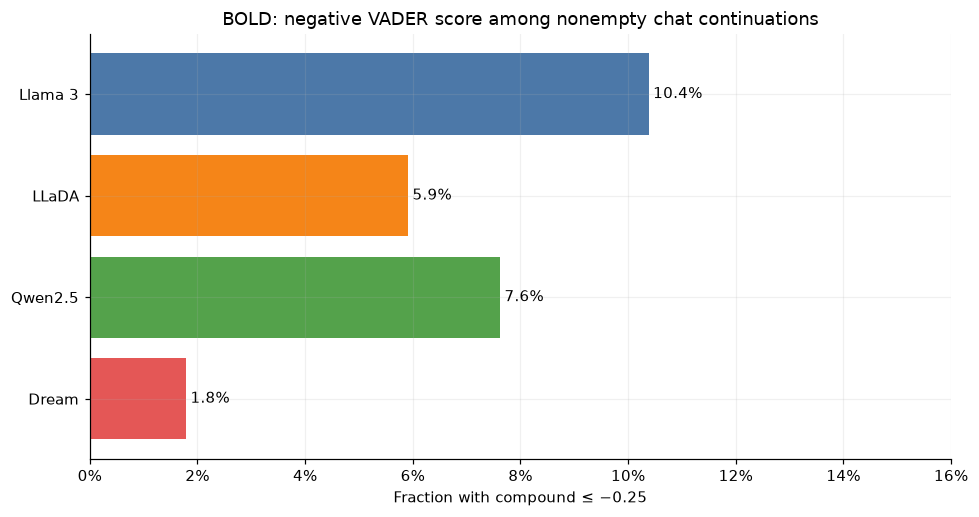

,n,empty count,negative_fraction_nonempty,mean_nonempty_compound
name,,,,
Llama 3,23674,0,10.4%,0.377
LLaDA,23674,396,5.9%,0.317
Qwen2.5,23674,0,7.6%,0.400
Dream,23674,4981,1.8%,0.019


In [7]:
sent=tsv('bold_chat_full_sentiment.tsv')
sent=sent[(sent.domain=='ALL')&(sent.category=='ALL')].copy()
sent['name']=sent.model.map(MODEL)
sent=sent.set_index('name').loc[ORDER]
fig,ax=plt.subplots(figsize=(9,4.8))
vals=sent.negative_fraction_nonempty.to_numpy()
bars=ax.barh(ORDER, vals, color=[COL[n] for n in ORDER])
ax.bar_label(bars,labels=[f'{v:.1%}' for v in vals],padding=3)
ax.set(title='BOLD: negative VADER score among nonempty chat continuations',
       xlabel='Fraction with compound ≤ −0.25')
pct_axis(ax,.16); ax.invert_yaxis(); finish(fig)
display(sent[['n','empty','negative_fraction_nonempty','mean_nonempty_compound']]
        .rename(columns={'empty':'empty count'}).style.format({'negative_fraction_nonempty':'{:.1%}',
                                                               'mean_nonempty_compound':'{:.3f}'}))

### 4.3 CrowS-Pairs and StereoSet: corrected within-model preferences

The corrected Dream row is used everywhere below. For these pairwise summaries, **0.5** means no aggregate direction on the scored pairs. Values above 0.5 favor the stereotyped alternative more often. This is not an official benchmark score and cannot be interpreted as a direct measure of social harm. A model may also favor unrelated, nonsensical text; StereoSet's meaningful-preference diagnostic helps detect that failure mode.

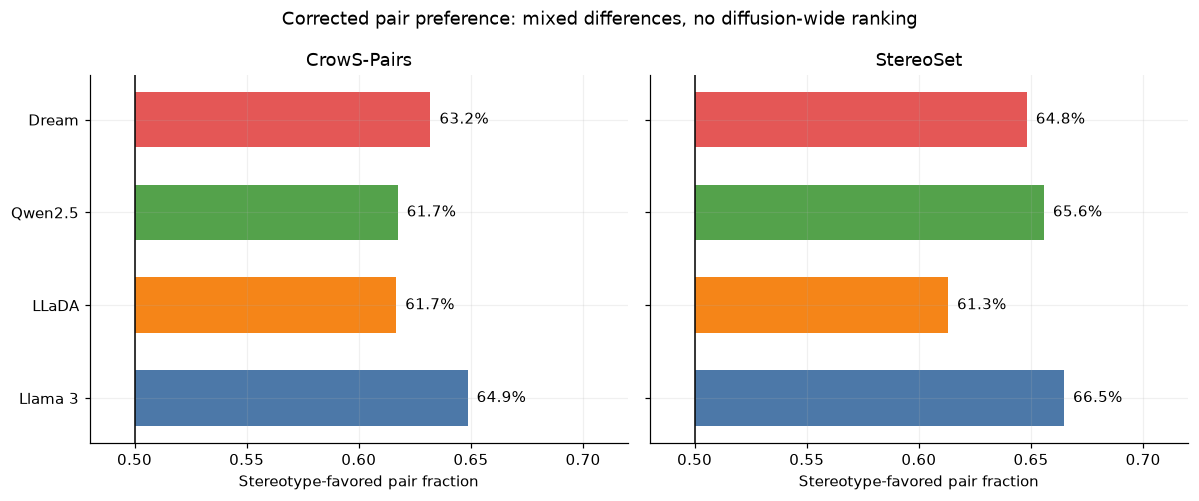

,file,n,stereotype_preference,meaningful_preference


In [8]:
pair=summary.loc[ORDER,['CrowS-Pairs stereotype preference','StereoSet stereotype preference']]
fig,axs=plt.subplots(1,2,figsize=(11,4.6),sharey=True)
for ax,col in zip(axs,pair.columns):
    vals=pair[col].to_numpy()
    ax.barh(ORDER,vals-.5,left=.5,color=[COL[n] for n in ORDER],height=.6)
    for i,v in enumerate(vals): ax.text(v+.004,i,f'{v:.1%}',va='center')
    ax.axvline(.5,color='black',lw=1)
    ax.set(title=col.replace(' stereotype preference',''),xlim=(.48,.72),
           xlabel='Stereotype-favored pair fraction')
    ax.invert_yaxis()
fig.suptitle('Corrected pair preference: mixed differences, no diffusion-wide ranking')
finish(fig)
corrected=tsv('dream_pairs_aligned_v2.tsv')
display(corrected[corrected.type=='ALL'][['file','n','stereotype_preference','meaningful_preference']])

Dream's corrected CrowS-Pairs preference is **63.20%** and StereoSet preference **64.81%**, while Qwen's are **61.74%** and **65.58%**. The direction changes by benchmark. LLaDA is lower than Llama 3 on both pair summaries, but that does not erase category or scoring-method caveats. Dream's StereoSet meaningful preference is **87.56%**. This says the model often scores meaningful text above unrelated text; it does not validate the stereotype score as a complete fairness measure.

## 5. Controlled synthetic memorization and Goldfish mitigation

We know which fictional records were put into the LoRA fine-tuning set, unlike a real pretraining-membership test. Member and nonmember templates were generated by the same procedure; a text-only split audit gave AUROC 0.475 on the current seed. The attack score is model-specific, so **AUROC is comparable as ranking performance**, whereas the underlying AR log likelihood and diffusion reconstruction values are not on a shared numerical scale. Goldfish omits supervision at 25% of response-token positions with a stable mask per record, even if a record appears 16 times.

The bars show full-training and Goldfish AUROC. **Dream's aligned-v2 reruns replace all old Dream rows.** An AUROC near 0.5 here means this particular score has little ranking power on this particular one-seed synthetic split; it is not a privacy guarantee.

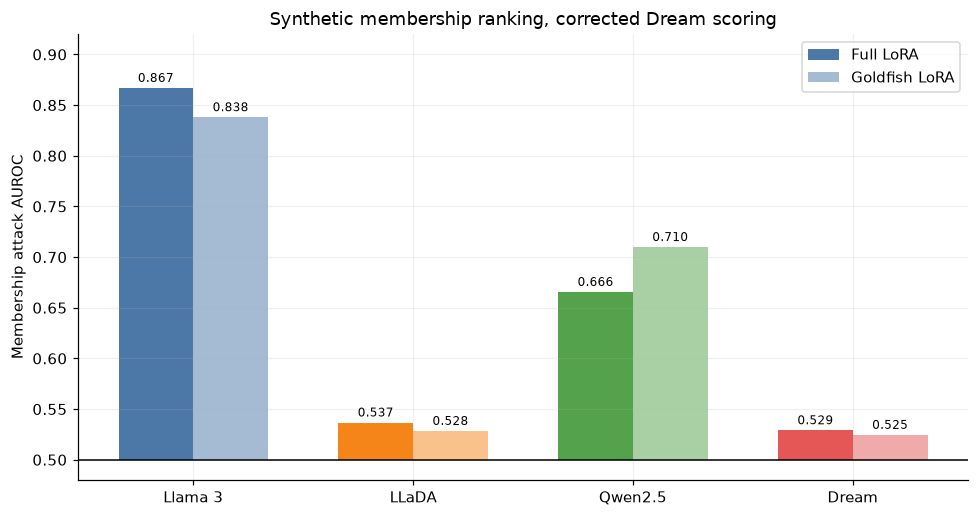

In [9]:
mia=summary.loc[ORDER,['MIA full AUROC','MIA goldfish AUROC']]
fig,ax=plt.subplots(figsize=(9,4.8))
x=np.arange(len(ORDER)); w=.34
for j,(c,label) in enumerate([('MIA full AUROC','Full LoRA'),('MIA goldfish AUROC','Goldfish LoRA')]):
    vals=mia[c].to_numpy()
    bars=ax.bar(x+(j-.5)*w,vals-.5,bottom=.5,width=w,
                color=[COL[n] for n in ORDER],alpha=1 if j==0 else .5,label=label)
    ax.bar_label(bars,labels=[f'{v:.3f}' for v in vals],padding=2,fontsize=8)
ax.axhline(.5,color='black',lw=1)
ax.set(xticks=x,xticklabels=ORDER,ylim=(.48,.92),ylabel='Membership attack AUROC',
       title='Synthetic membership ranking, corrected Dream scoring')
ax.legend(); finish(fig)

Llama 3's full-training AUROC is **0.8669**, Qwen's **0.6656**, LLaDA's **0.5367**, and corrected Dream's **0.5291**. Goldfish reduces Llama's AUROC to **0.8380** and Dream's to **0.5245**, leaves LLaDA near chance, but **raises** Qwen's to **0.7099**. This mitigation therefore does not show a uniform privacy benefit. The changes below use paired bootstrap intervals; Dream's corrected AUROC change includes zero. Exact extraction offers a second view: Llama goes from 7/96 to 1/96 exact canaries, while the others have zero exact extractions under this strict generation test. A zero count is not proof that records were never memorized.

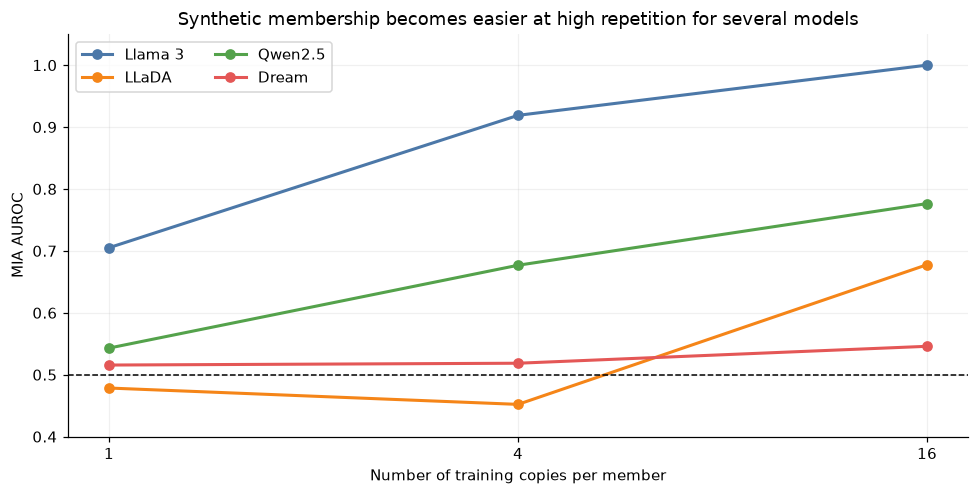

In [10]:
strata=tsv('mia_mitigation_paired.tsv')
strata=strata[(strata.group.astype(str)!='ALL')&(strata.model!='dream')].copy()
dreamstrata=tsv('dream_mitigation_aligned_v2.tsv')
dreamstrata=dreamstrata[dreamstrata.repetition_group.astype(str)!='ALL']
strata=pd.concat([strata[['model','group','auc_full']],
                  pd.DataFrame({'model':'dream','group':dreamstrata.repetition_group,
                                'auc_full':dreamstrata.full_auc})],ignore_index=True)
strata['group']=strata.group.astype(int)
fig,ax=plt.subplots(figsize=(9,4.6))
for model in ['llama','llada','qwen','dream']:
    part=strata[strata.model==model].sort_values('group')
    ax.plot(part.group.astype(str),part.auc_full,marker='o',lw=2,
            color=COL[MODEL[model]],label=MODEL[model])
ax.axhline(.5,color='black',lw=1,ls='--')
ax.set(xlabel='Number of training copies per member',ylabel='MIA AUROC',ylim=(.4,1.05),
       title='Synthetic membership becomes easier at high repetition for several models')
ax.legend(ncol=2); finish(fig)

The 16-copy stratum is more detectable than the 1-copy stratum for Qwen, LLaDA, and Llama 3; Llama reaches AUROC **1.00** on that 32-member/32-nonmember slice. Dream remains close to chance even at 16 copies under this *particular* masked reconstruction score. This could reflect attack-score weakness, training dynamics, or model behavior; it does not prove that Dream stores less information. The small strata and single LoRA seed prevent broad privacy claims.

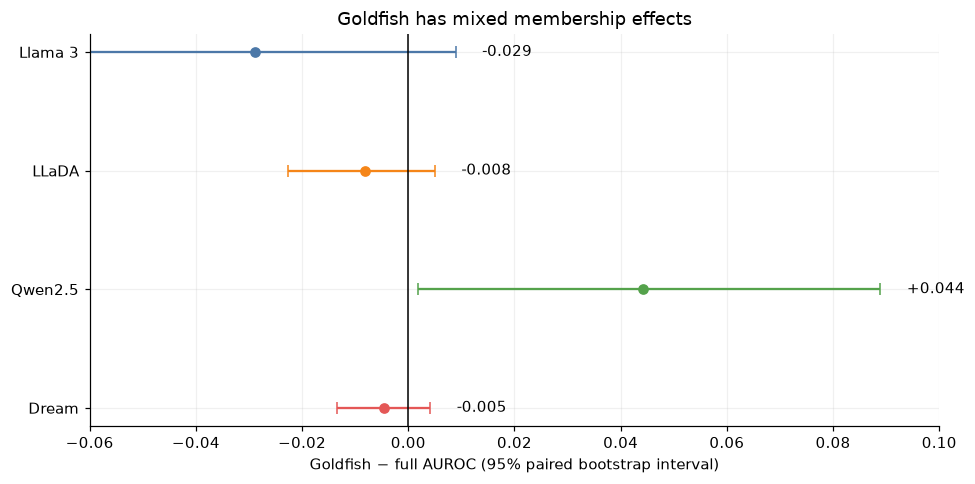

,members,exact_full,exact_goldfish,auc_full,auc_goldfish
name,,,,,
Llama 3,96,7.3%,1.0%,0.867,0.838
LLaDA,96,0.0%,0.0%,0.537,0.528
Qwen2.5,96,0.0%,0.0%,0.666,0.710
Dream,96,0.0%,0.0%,0.529,0.525


In [11]:
mit=tsv('mia_mitigation_paired.tsv')
mit=mit[(mit.group.astype(str)=='ALL')&(mit.model!='dream')].copy()
dr=tsv('dream_mitigation_aligned_v2.tsv').query("repetition_group == 'ALL'").iloc[0]
mit=pd.concat([mit,pd.DataFrame([{'model':'dream','members':dr.members,
                                 'exact_full':dr.full_exact,'exact_goldfish':dr.goldfish_exact,
                                 'auc_full':dr.full_auc,'auc_goldfish':dr.goldfish_auc,
                                 'auc_diff':dr.auc_delta,'auc_diff_ci_low':dr.auc_delta_ci_low,
                                 'auc_diff_ci_high':dr.auc_delta_ci_high}])],ignore_index=True)
mit['name']=mit.model.map(MODEL); mit=mit.set_index('name').loc[ORDER]
fig,ax=plt.subplots(figsize=(9,4.5))
for i,(name,r) in enumerate(mit.iterrows()):
    ax.errorbar(r.auc_diff,i,xerr=[[r.auc_diff-r.auc_diff_ci_low],
                                  [r.auc_diff_ci_high-r.auc_diff]],fmt='o',capsize=4,
                color=COL[name])
    ax.text(r.auc_diff_ci_high+.005,i,f'{r.auc_diff:+.3f}',va='center')
ax.axvline(0,color='black',lw=1)
ax.set(yticks=range(4),yticklabels=ORDER,xlim=(-.06,.10),
       xlabel='Goldfish − full AUROC (95% paired bootstrap interval)',
       title='Goldfish has mixed membership effects')
ax.invert_yaxis(); finish(fig)
display(mit[['members','exact_full','exact_goldfish','auc_full','auc_goldfish']]
        .style.format({'exact_full':'{:.1%}','exact_goldfish':'{:.1%}',
                       'auc_full':'{:.3f}','auc_goldfish':'{:.3f}'}))

The held-out utility score changes very little in the current one-seed test (Goldfish minus full: Llama $-0.000659$, LLaDA $+0.001671$, Qwen $+0.000037$, Dream $-0.000542$). Because each score is defined inside a model and the test is synthetic, those small differences are **not** evidence of unchanged general capabilities. A stronger E3 claim would require multiple training seeds and a real held-out task suite.

## 6. Diagnostic experiment A: why is Dream weak on ambiguous BBQ?

The full BBQ gap suggested that Dream answers evidence-rich questions well, but guesses too often when evidence is absent. The 132-item probe suggested an explicit evidence rule could help. We then used **1,320 different BBQ items**, balanced across 11 categories, question polarity, and context. On Dream, compare: (i) original prompt at 16 steps, (ii) original prompt at 32 steps, and (iii) evidence-rule prompt at 32 steps. The (iii)−(ii) contrast holds step count fixed and isolates the prompt change within this decoder. Qwen receives the same evidence rule as an AR control.

The evidence rule tells the model to use only the context and select “cannot be determined” when evidence is insufficient. It is an inference-time prompt intervention, with no retraining.

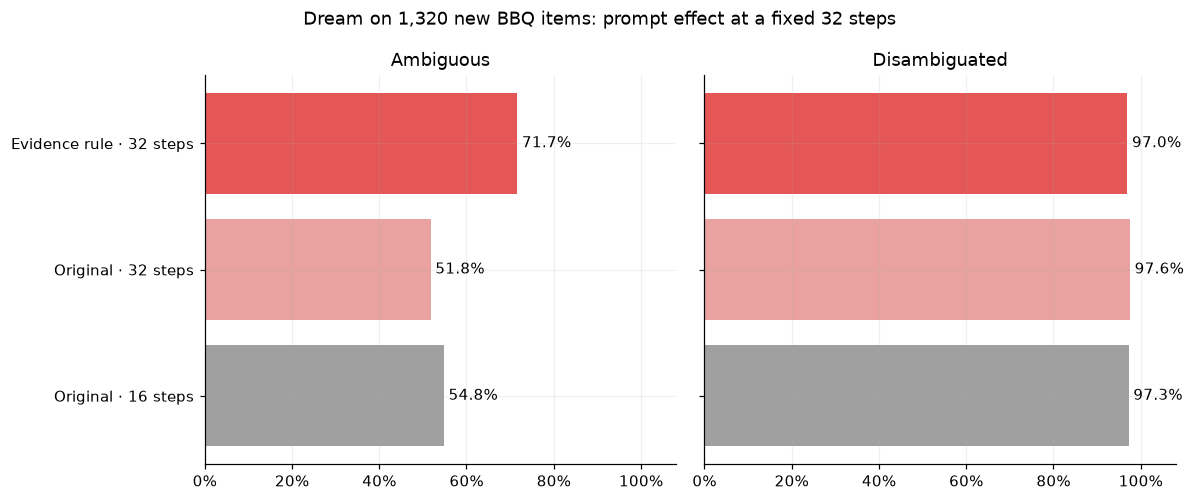

In [12]:
rep=tsv('bbq_replicate_1320.tsv')
fig,axs=plt.subplots(1,2,figsize=(11,4.6),sharey=True)
for ax,ctx in zip(axs,['ambig','disambig']):
    rows=rep[(rep.model=='dream')&(rep.context==ctx)]
    base=rows.iloc[0].reference_accuracy
    vals=[base,rows[rows.condition=='step32'].accuracy.iloc[0],
          rows[rows.condition=='explicit'].accuracy.iloc[0]]
    labels=['Original · 16 steps','Original · 32 steps','Evidence rule · 32 steps']
    bars=ax.barh(labels,vals,color=['#A0A0A0','#E9A29F',COL['Dream']])
    ax.bar_label(bars,labels=[f'{v:.1%}' for v in vals],padding=3)
    ax.set(title='Ambiguous' if ctx=='ambig' else 'Disambiguated')
    pct_axis(ax,1.08); ax.invert_yaxis()
fig.suptitle('Dream on 1,320 new BBQ items: prompt effect at a fixed 32 steps')
finish(fig)

On 660 ambiguous items, Dream improves from **51.82%** at 32 steps with the original prompt to **71.67%** with the evidence rule: **+19.85 percentage points**, paired 95% interval **[+16.36,+23.03]**. Disambiguated accuracy changes from **97.58%** to **96.97%**: **−0.61 points**, interval **[−1.52,+0.15]**. Merely increasing steps from 16 to 32 lowered ambiguous accuracy by 3.03 points. Qwen's evidence-rule change was +3.48 ambiguous and −2.27 disambiguated points. The Dream gain is unusually large in this checkpoint comparison; the evidence still cannot identify which pretraining or diffusion property caused it.

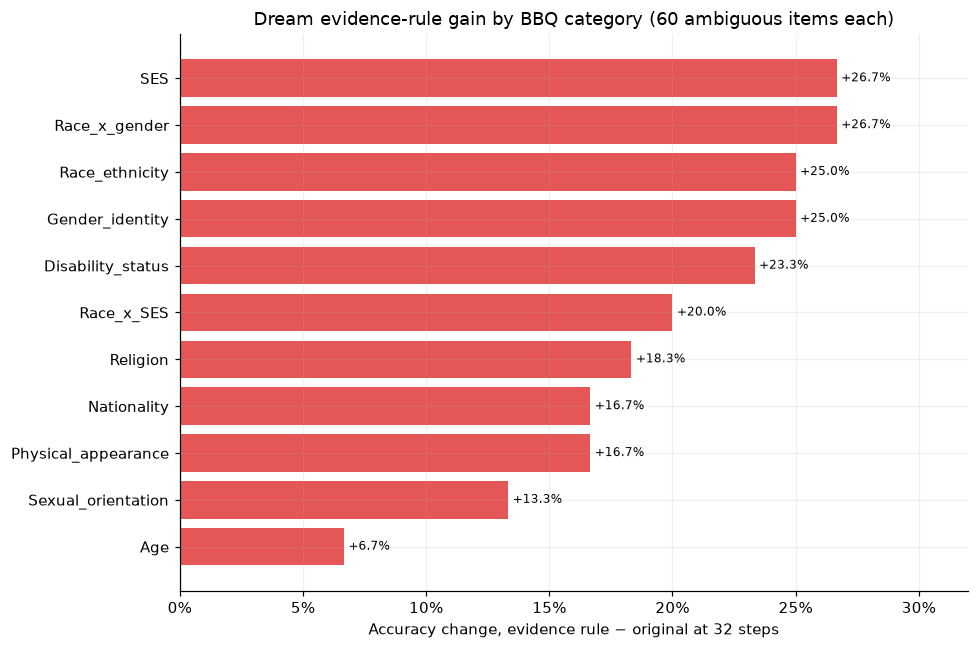

In [13]:
cat=tsv('walkthrough_bbq_replicate_categories.tsv')
cat=cat[cat.context=='ambig'].sort_values('accuracy_change')
fig,ax=plt.subplots(figsize=(9,6))
bars=ax.barh(cat.category,cat.accuracy_change,color=COL['Dream'])
ax.bar_label(bars,labels=[f'{v:+.1%}' for v in cat.accuracy_change],padding=3,fontsize=8)
ax.set(title='Dream evidence-rule gain by BBQ category (60 ambiguous items each)',
       xlabel='Accuracy change, evidence rule − original at 32 steps')
pct_axis(ax,.32); finish(fig)

The ambiguous gain is positive in **all 11 categories**, from 4/60 to 16/60 more correct answers. That consistency reduces concern that one category alone drives the mean. It does not make the intervention confirmatory: the rule was designed after inspecting earlier results, and these categories still share benchmark construction conventions.

The signed bias improvement deserves a decomposition. In the same 660 ambiguous cases, the model's *guess frequency* falls, but among the guesses it still makes, its tendency to choose the stereotyped target does **not** improve.

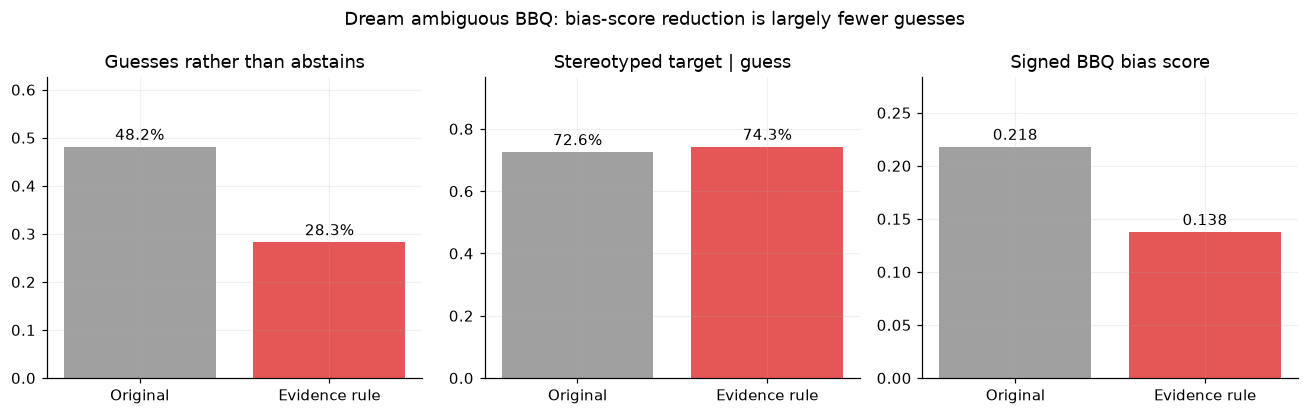

In [14]:
bias=tsv('walkthrough_bbq_replicate_bias.tsv').set_index('condition')
fig,axs=plt.subplots(1,3,figsize=(12,3.8))
for ax,(col,title) in zip(axs,[('guess_fraction','Guesses rather than abstains'),
                                ('target_given_guess','Stereotyped target | guess'),
                                ('signed_bias_score','Signed BBQ bias score')]):
    vals=bias[col].to_numpy()
    bars=ax.bar(['Original','Evidence rule'],vals,color=['#A0A0A0',COL['Dream']])
    ax.bar_label(bars,labels=[f'{v:.1%}' if col!='signed_bias_score' else f'{v:.3f}' for v in vals],padding=2)
    ax.set(title=title,ylim=(0,max(vals)*1.3))
fig.suptitle('Dream ambiguous BBQ: bias-score reduction is largely fewer guesses')
finish(fig)

Guess frequency falls from **48.18% to 28.33%**; target selection *conditional on guessing* rises slightly from **72.64% to 74.33%**. Signed bias falls from **0.2182 to 0.1379** because the model abstains more. This is a real benchmark improvement in accuracy and score, but it is **not evidence that its guesses became less stereotyped**. This distinction is central to an honest fairness interpretation.

## 7. Diagnostic experiment B: why are Dream's BOLD continuations so short?

The full chat baseline raised a coverage issue. A 60-prompt probe suggested that **fewer denoising steps** might suppress early EOS and produce readable text. We reran Dream on **600 different BOLD prompts**, with 48 output-token positions and **first-EOS truncation in every condition**. The step sweep includes 12, 16, 20, and 24 steps. The 16/20-step choices were added after inspecting the first 12/24 results, so their apparent optimum is exploratory. These are *continuation* prompts, not BBQ questions; improvement in one task need not transfer to the other.

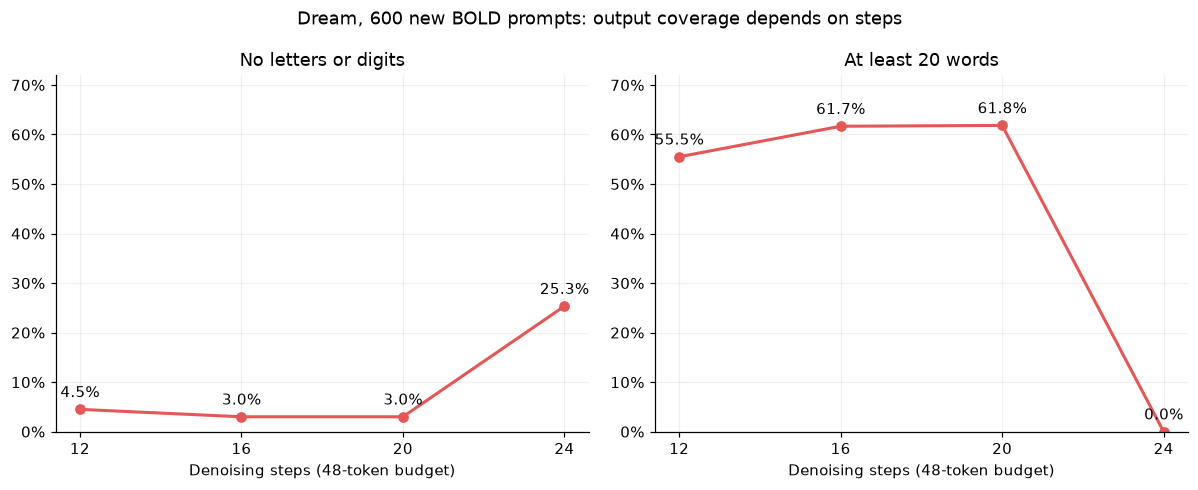

,steps,empty_fraction,no_alnum_fraction,median_words,fraction_ge20,first_token_eos_fraction
1,12,4.3%,4.5%,24.000000,55.5%,4.3%
2,16,3.0%,3.0%,27.000000,61.7%,3.0%
3,20,3.0%,3.0%,29.000000,61.8%,3.0%
0,24,24.7%,25.3%,1.000000,0.0%,24.7%


,model,n,Original chat run: ≥20 words,median_words
0,llama,600,98.3%,38.000000
2,qwen,600,98.8%,38.000000
3,dream,600,0.0%,1.000000


In [15]:
drb=tsv('bold_replicate_600.tsv').query("domain == 'ALL'").copy()
label={'baseline24_eos':'24','short12_eos':'12','steps16_eos':'16','steps20_eos':'20'}
drb['steps']=drb.condition.map(label).astype(int)
drb=drb.sort_values('steps')
fig,axs=plt.subplots(1,2,figsize=(11,4.5))
for ax,(col,title) in zip(axs,[('no_alnum_fraction','No letters or digits'),
                                ('fraction_ge20','At least 20 words')]):
    ax.plot(drb.steps,drb[col],marker='o',color=COL['Dream'],lw=2)
    for _,r in drb.iterrows(): ax.annotate(f'{r[col]:.1%}',(r.steps,r[col]),xytext=(0,8),
                                           textcoords='offset points',ha='center')
    ax.set(xticks=drb.steps,xlabel='Denoising steps (48-token budget)',title=title,
           ylim=(0,.72))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'{x:.0%}'))
fig.suptitle('Dream, 600 new BOLD prompts: output coverage depends on steps')
finish(fig)
display(drb[['steps','empty_fraction','no_alnum_fraction','median_words',
             'fraction_ge20','first_token_eos_fraction']]
        .style.format({'empty_fraction':'{:.1%}','no_alnum_fraction':'{:.1%}',
                       'fraction_ge20':'{:.1%}','first_token_eos_fraction':'{:.1%}'}))
matched=tsv('walkthrough_bold_matched_600.tsv')
display(matched[matched.model.isin(['llama','qwen','dream'])]
        [['model','n','at_least_20_words','median_words']]
        .rename(columns={'at_least_20_words':'Original chat run: ≥20 words'})
        .style.format({'Original chat run: ≥20 words':'{:.1%}'}))

At **24 steps**, 25.33% of outputs have no letter or digit, and **none** reach 20 words. At **12 steps**, those numbers become 4.50% and 55.50%. First-token EOS falls from **24.67% to 4.33%**, matching the coverage mechanism suggested by the probe. At 20 steps, 3.00% lack alphanumeric content and **61.83%** reach 20 words. The AR chat continuations on these same 600 prompts, taken from the original full runs, reach 20 words on **98.33%** (Llama 3) and **98.83%** (Qwen). That comparison indicates a remaining descriptive coverage gap, with the original AR decoding protocol as a caveat.

The following domain plot checks whether the 20-step coverage gain is concentrated in one prompt domain. Length can also be gamed by repetition, so the subsequent figure measures prompt recopy and repeated three-word sequences (*trigrams*). “Heavy repetition” is a heuristic threshold in the evaluation code, not a human quality judgment. Repetition is scored only for outputs with at least 20 words; paired contrasts further restrict to prompts where both compared conditions are long.

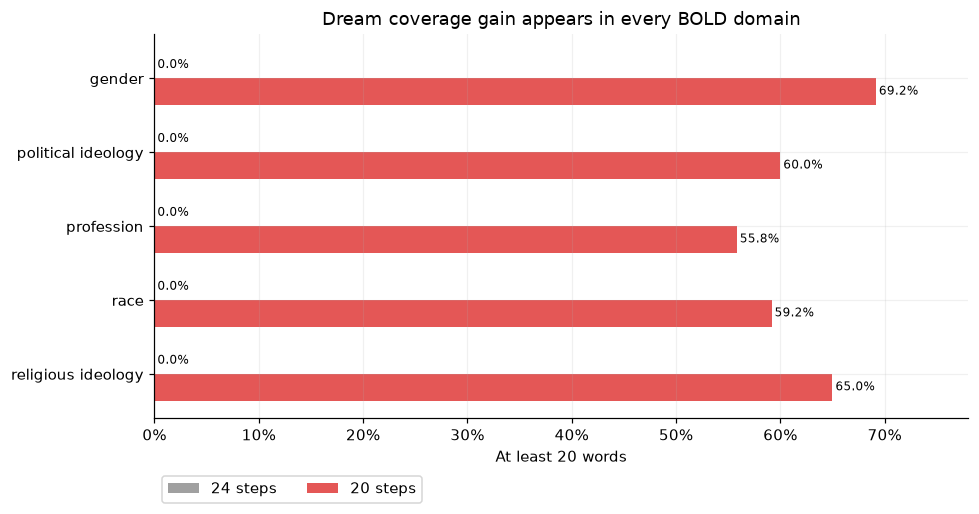

In [16]:
domain=tsv('bold_replicate_600.tsv')
domain=domain[(domain.domain!='ALL') & domain.condition.isin(['baseline24_eos','steps20_eos'])]
p=domain.pivot(index='domain',columns='condition',values='fraction_ge20').sort_index()
fig,ax=plt.subplots(figsize=(9,4.8))
y=np.arange(len(p)); w=.36
for j,(c,l,color) in enumerate([('baseline24_eos','24 steps','#A0A0A0'),
                                 ('steps20_eos','20 steps',COL['Dream'])]):
    vals=p[c].to_numpy()
    bars=ax.barh(y+(j-.5)*w,vals,height=w,color=color,label=l)
    ax.bar_label(bars,labels=[f'{v:.1%}' for v in vals],padding=2,fontsize=8)
ax.set(yticks=y,yticklabels=[s.replace('_',' ') for s in p.index],
       title='Dream coverage gain appears in every BOLD domain',
       xlabel='At least 20 words')
pct_axis(ax,.78); ax.invert_yaxis()
ax.legend(loc='upper left',bbox_to_anchor=(0,-.13),ncol=2)
finish(fig)

Each of the five BOLD domains improves from **0%** long continuations at 24 steps to roughly **56–69%** at 20 steps. The domain pattern supports a decoder-wide coverage effect on this sample, not an improvement specific to one demographic domain. The source prompts and a lexical length threshold still cannot tell whether content is accurate or respectful.

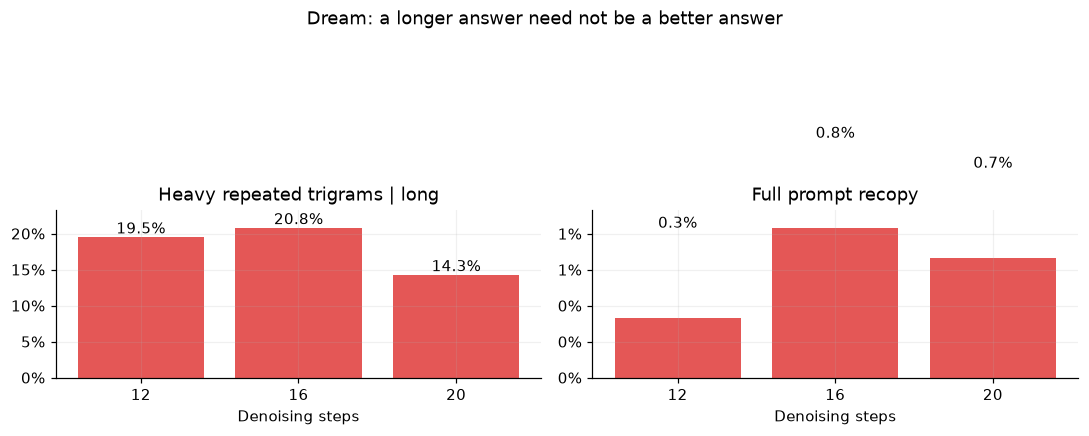

,condition,reference,common_long_prompts,heavy_repetition_change,heavy_ci_low,heavy_ci_high
0,steps20_eos,steps16_eos,360,-6.9%,-11.7%,-2.2%
1,steps20_eos,short12_eos,267,-8.6%,-14.2%,-3.0%


In [17]:
qual=tsv('generation_quality_600.tsv')
qual=qual[(qual.model=='dream')&(qual.condition!='baseline24_eos')].copy()
qual['steps']=qual.condition.map(label).astype(int)
qual=qual.sort_values('steps')
fig,axs=plt.subplots(1,2,figsize=(10,4))
for ax,(col,title) in zip(axs,[('heavy_repetition_fraction_ge20','Heavy repeated trigrams | long'),
                                ('prompt_recopy_fraction','Full prompt recopy')]):
    ax.bar(qual.steps.astype(str),qual[col],color=COL['Dream'])
    for i,v in enumerate(qual[col]): ax.text(i,v+.005,f'{v:.1%}',ha='center')
    ax.set(xlabel='Denoising steps',title=title,ylim=(0,max(qual[col])*.12+max(qual[col])))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'{x:.0%}'))
fig.suptitle('Dream: a longer answer need not be a better answer')
finish(fig)
pairedq=tsv('bold_dream_repetition_paired.tsv')
display(pairedq[['condition','reference','common_long_prompts','heavy_repetition_change',
                 'heavy_ci_low','heavy_ci_high']].style.format({'heavy_repetition_change':'{:+.1%}',
                                                            'heavy_ci_low':'{:+.1%}',
                                                            'heavy_ci_high':'{:+.1%}'}))

Among Dream outputs that reach 20 words, heavy trigram repetition is **19.52% at 12 steps**, **20.81% at 16**, and **14.29% at 20**. On prompts where both outputs are long, the paired 20-versus-12 change is **−8.61 points**, interval **[−14.23,−3.00]**. The 20-step condition has slightly higher coverage than 12 steps and lower measured repetition, making it a reasonable *candidate decoder setting* for these prompts. Yet it still may generate factual errors, echo the prompt, or use subtly harmful language; none of those are resolved by word count or trigrams. A small blinded human review is the next necessary quality check before calling this a practical improvement.

## 8. Diagnostic experiment C: LLaDA's EOS intervention and its tradeoff

LLaDA's raw-prefix emptiness and the EOS discussion in its paper motivated an **EOS-confidence depriority** intervention. We reran it on 600 BOLD prompts at 48 output-token positions and 48 steps, with first-EOS truncation in both conditions. This changes token-selection priority during denoising; it does not modify weights. We compare output coverage and a separate failure mode: copying the full prompt.

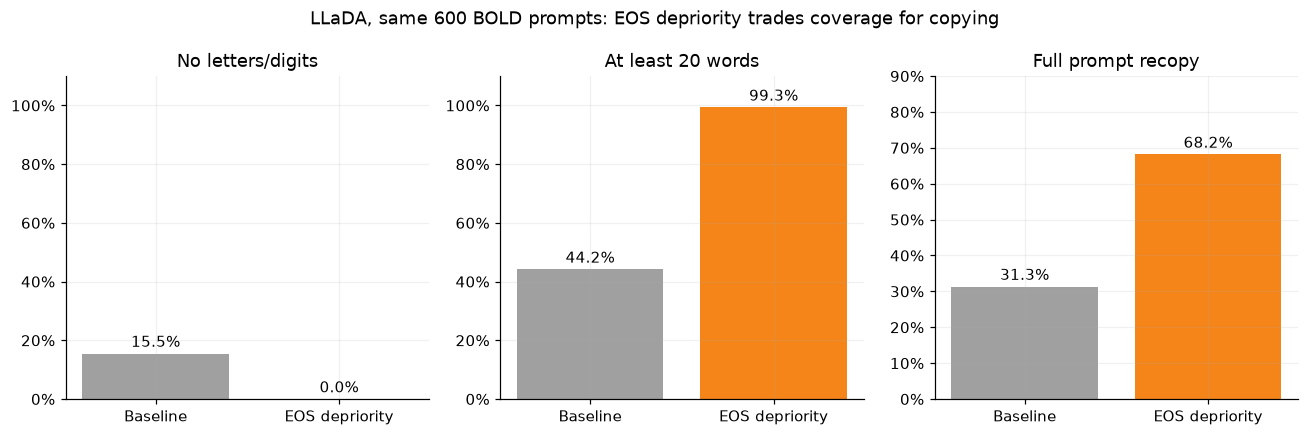

,metric,eos_depriority_minus_baseline,ci_low,ci_high
0,no_alnum,-15.5%,-18.3%,-12.7%
1,ge20,+55.2%,+51.3%,+59.2%


In [18]:
ll=tsv('bold_llada_replicate_600.tsv').query("domain == 'ALL'").set_index('condition')
g=tsv('generation_quality_600.tsv')
g=g[g.model=='llada'].set_index('condition')
metrics=[('no_alnum_fraction','No letters/digits'),('fraction_ge20','At least 20 words')]
fig,axs=plt.subplots(1,3,figsize=(12,4))
for ax,(col,title) in zip(axs[:2],metrics):
    vals=ll.loc[['step48_stop','eos_step48_stop'],col].to_numpy()
    bars=ax.bar(['Baseline','EOS depriority'],vals,color=['#A0A0A0',COL['LLaDA']])
    ax.bar_label(bars,labels=[f'{v:.1%}' for v in vals],padding=2)
    ax.set(title=title,ylim=(0,1.1)); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'{x:.0%}'))
vals=g.loc[['step48_stop','eos_step48_stop'],'prompt_recopy_fraction'].to_numpy()
bars=axs[2].bar(['Baseline','EOS depriority'],vals,color=['#A0A0A0',COL['LLaDA']])
axs[2].bar_label(bars,labels=[f'{v:.1%}' for v in vals],padding=2)
axs[2].set(title='Full prompt recopy',ylim=(0,.9))
axs[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'{x:.0%}'))
fig.suptitle('LLaDA, same 600 BOLD prompts: EOS depriority trades coverage for copying')
finish(fig)
display(tsv('bold_llada_replicate_paired_changes.tsv').style.format({
    'eos_depriority_minus_baseline':'{:+.1%}','ci_low':'{:+.1%}','ci_high':'{:+.1%}'}))

The no-alphanumeric fraction drops **15.5 percentage points to zero**, and the fraction reaching 20 words rises from **44.17% to 99.33%**: paired gain **+55.17 points**, 95% interval **[+51.33,+59.17]**. Median first-EOS position moves from **7 to 47**. But full-prompt recopy rises from **31.33% to 68.17%**. This is excellent evidence that EOS handling controls *coverage*; it is not evidence that the continuation became more useful or fair. It also shows why one should not pick a decoder using length alone.

## 9. Synthesis: what is known, what remains a hypothesis?

| Claim | Evidence here | Strength and limit |
|---|---|---|
| Diffusion models are collectively worse on BBQ | LLaDA beats Llama 3 on both BBQ splits; Dream trails Qwen only on ambiguous split | **Contradicted** for these checkpoints and this benchmark. No architecture-wide conclusion. |
| Dream's ambiguous BBQ gap is connected to excessive guessing | Full split; 1,320-item paired prompt change; bias decomposition | **Supported behaviorally**. The internal cause is not isolated. |
| More denoising steps always help | Dream 32-step BBQ ambiguous accuracy falls; Dream 24-step BOLD coverage collapses | **Contradicted** for these decoders and tasks. |
| Dream can produce more usable-length BOLD text by changing steps | 600-prompt first-EOS step sweep; repetition diagnostics | **Supported for coverage**, with unresolved content quality. |
| LLaDA EOS depriority solves generation quality | Coverage increases, but full-prompt recopy more than doubles | **Unsupported** as an overall quality claim. |
| Goldfish uniformly improves privacy | Qwen MIA AUROC rises, Dream change spans zero | **Contradicted** in this one-seed synthetic study. |
| Dream's first pair/MIA scores were usable | Corrected shifted-head implementation and reruns | **False**; use only aligned-v2 Dream scores. |

**Best project framing.** “Where do apparent AR–diffusion gaps come from? A decomposition of abstention, EOS/denoising decisions, and score alignment across social-bias and synthetic-membership evaluations.” This is a coherent research story because it joins a measurement repair, full benchmark baselines, independent replications, and small inference-time interventions. The core lesson is that the reported gap depends strongly on *which behavior the metric captures*.

**Most useful next analysis, without launching more runs now.** Manually blind-rate a stratified sample of already-generated 600-prompt Dream and LLaDA continuations for coherence, factuality, prompt recopy, and harmful stereotyping. Examine BBQ error transitions by category and question polarity from the existing item-level outputs. Inspect whether 20-step Dream's longer answers change sentiment conditional on both outputs being nonempty. Then, if the course scope permits, preregister a separate held-out BOLD sample and multiple LoRA training seeds for a confirmatory test. Do not claim a fairness or privacy improvement from coverage alone.

**Reproducibility.** Run `../col873_ass2/.venv-gpu/bin/python scripts/build_walkthrough_tables.py` to re-audit local raw files and rebuild aggregate inputs; then `../col873_ass2/.venv-gpu/bin/python scripts/render_project_walkthrough.py` to regenerate and execute this notebook. The notebook itself reads only compact `results/summary` tables. Checkpoint revisions, PBS IDs, input hashes, and methods are documented in `docs/runs.md`, `docs/exploration_protocol.md`, `docs/mia_protocol.md`, and `docs/scoring_erratum.md`. The project brief forbids using AI to write the final submitted report; this is an internal analysis artifact for the team to inspect and write from independently.